In [ ]:
!pip install -q kagglehub

import kagglehub, glob, os
dataset_path = kagglehub.dataset_download("razanihababdellatif/emergency-dispatch-and-traffic-physics-dataset")
csv_file_list = glob.glob(dataset_path + "/**/*.csv", recursive=True)
print(csv_file_list)
csv_file_path = max(csv_file_list, key=os.path.getsize)
print("Using:", csv_file_path)

Using Colab cache for faster access to the 'emergency-dispatch-and-traffic-physics-dataset' dataset.
['/kaggle/input/emergency-dispatch-and-traffic-physics-dataset/synthetic_traffic_benchmark_200k.csv']
Using: /kaggle/input/emergency-dispatch-and-traffic-physics-dataset/synthetic_traffic_benchmark_200k.csv


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

raw_dataframe = pd.read_csv(csv_file_path)
print("Full shape:", raw_dataframe.shape)
print(raw_dataframe.dtypes)

TIME_COLUMN = None
for column_name in raw_dataframe.columns:
    if "time" in column_name.lower() or "date" in column_name.lower():
        converted_values = pd.to_datetime(raw_dataframe[column_name], errors="coerce")
        if converted_values.notna().mean() > 0.8:
            TIME_COLUMN = column_name
            raw_dataframe[column_name] = converted_values
            break

if TIME_COLUMN is not None:
    raw_dataframe = raw_dataframe.dropna(subset=[TIME_COLUMN]).sort_values(TIME_COLUMN)
else:
    TIME_COLUMN = "synthetic_time"
    raw_dataframe[TIME_COLUMN] = pd.date_range("2024-01-01", periods=len(raw_dataframe), freq="1min")

dataframe = raw_dataframe.head(10000).reset_index(drop=True)


TARGET_COLUMN = None
if TARGET_COLUMN is None:
    for keyword in ["congestion", "density", "speed"]:
        for column_name in dataframe.columns:
            if keyword in column_name.lower() and column_name != TIME_COLUMN:
                TARGET_COLUMN = column_name
                break
        if TARGET_COLUMN is not None:
            break
print("TIME COLUMN :", TIME_COLUMN)
print("TARGET COLUMN:", TARGET_COLUMN)

for column_name in list(dataframe.columns):
    if column_name in (TIME_COLUMN, TARGET_COLUMN):
        continue
    if dataframe[column_name].dtype == "object" and dataframe[column_name].nunique() > 0.5 * len(dataframe):
        dataframe = dataframe.drop(columns=[column_name])
    elif np.issubdtype(dataframe[column_name].dtype, np.datetime64):
        dataframe = dataframe.drop(columns=[column_name])

for column_name in dataframe.columns:
    if column_name == TIME_COLUMN:
        continue
    if dataframe[column_name].dtype == "object":
        dataframe[column_name] = dataframe[column_name].fillna(dataframe[column_name].mode()[0])
    else:
        dataframe[column_name] = dataframe[column_name].fillna(dataframe[column_name].median())

ordered_levels = {"none": 0, "free": 0, "low": 1, "light": 1, "moderate": 2, "medium": 2,
                  "high": 3, "heavy": 3, "severe": 4, "critical": 4}
for column_name in dataframe.columns:
    if column_name == TIME_COLUMN or dataframe[column_name].dtype != "object":
        continue
    lowered_values = dataframe[column_name].astype(str).str.lower().str.strip()
    if column_name == TARGET_COLUMN and set(lowered_values.unique()).issubset(ordered_levels.keys()):
        dataframe[column_name] = lowered_values.map(ordered_levels)
    else:
        dataframe[column_name] = LabelEncoder().fit_transform(dataframe[column_name].astype(str))

print("Missing values left:", dataframe.drop(columns=[TIME_COLUMN]).isnull().sum().sum())
dataframe.head()

Full shape: (200000, 29)
Record_ID                               object
Timestamp                               object
Date                                    object
Hour                                     int64
Month                                    int64
Day_of_Week                             object
Time_of_Day                             object
Is_Holiday                               int64
Area_Type                               object
Road_Type                               object
Intersection_Type                       object
Speed_Limit_kmh                          int64
Weather                                 object
Road_Condition                          object
Visibility_m                           float64
Congestion_Index                       float64
Vehicle_Type                            object
Driver_Age                             float64
Driver_Experience_yrs                  float64
Vehicle_Age_yrs                        float64
Recorded_Speed_kmh                 

,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,Intersection_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,2022-01-01 00:26:51.921181523,0,0,1,2,3,0,2,2,0,...,8.2,119.5,6.5,0,1,0,3,2,0.0,0.0
1,2022-01-01 00:54:17.552135483,0,0,1,2,3,0,1,1,2,...,1.2,46.5,11.9,0,1,0,3,2,0.0,0.0
2,2022-01-01 02:13:16.435408441,0,2,1,2,3,0,1,2,0,...,10.7,114.6,11.4,0,1,0,3,2,0.0,0.0
3,2022-01-01 02:28:00.995132411,0,2,1,2,3,0,2,0,2,...,13.0,30.9,9.9,0,1,0,3,2,0.0,0.0
4,2022-01-01 02:34:50.686431926,0,2,1,2,3,0,2,1,2,...,15.1,31.5,4.7,0,1,0,3,2,0.0,0.0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

dataframe = dataframe.sort_values(TIME_COLUMN).set_index(TIME_COLUMN)

chosen_frequency = None
for frequency in ["h", "30min", "15min", "10min", "5min", "min"]:
    grouped_dataframe = dataframe.resample(frequency).mean()
    grouped_dataframe = grouped_dataframe.dropna(how="all")
    if len(grouped_dataframe) >= 500:
        chosen_frequency = frequency
        break
if chosen_frequency is None:
    chosen_frequency = "min"
    grouped_dataframe = dataframe.resample("min").mean().dropna(how="all")

grouped_dataframe = grouped_dataframe.interpolate().bfill().ffill()
print("Grouping interval:", chosen_frequency, "| Rows:", len(grouped_dataframe))

grouped_dataframe["hour_of_day"] = grouped_dataframe.index.hour
grouped_dataframe["day_of_week"] = grouped_dataframe.index.dayofweek
feature_dataframe = grouped_dataframe.reset_index(drop=True)

target_index = feature_dataframe.columns.get_loc(TARGET_COLUMN)
total_rows = len(feature_dataframe)
train_end = int(total_rows * 0.70)
validation_end = int(total_rows * 0.85)

feature_scaler = MinMaxScaler()
feature_scaler.fit(feature_dataframe.iloc[:train_end])
scaled_values = feature_scaler.transform(feature_dataframe)

WINDOW_SIZE = 24
def create_sequences(values, window_size, target_idx):
    input_list, output_list = [], []
    for i in range(len(values) - window_size):
        input_list.append(values[i:i + window_size])
        output_list.append(values[i + window_size, target_idx])
    return np.array(input_list), np.array(output_list)

X_all, y_all = create_sequences(scaled_values, WINDOW_SIZE, target_index)

train_count = train_end - WINDOW_SIZE
validation_count = validation_end - WINDOW_SIZE
X_train, y_train = X_all[:train_count], y_all[:train_count]
X_val, y_val = X_all[train_count:validation_count], y_all[train_count:validation_count]
X_test, y_test = X_all[validation_count:], y_all[validation_count:]
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

target_series = feature_dataframe[TARGET_COLUMN]
print("Lag-1 autocorrelation:", round(target_series.autocorr(lag=1), 4))

Grouping interval: h | Rows: 1676
Train: (1149, 24, 29) Val: (251, 24, 29) Test: (252, 24, 29)
Lag-1 autocorrelation: 0.661


Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0612 - mae: 0.2043 - val_loss: 0.0413 - val_mae: 0.1779 - learning_rate: 0.0010
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0434 - mae: 0.1695 - val_loss: 0.0399 - val_mae: 0.1777 - learning_rate: 0.0010
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0423 - mae: 0.1691 - val_loss: 0.0367 - val_mae: 0.1668 - learning_rate: 0.0010
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0377 - mae: 0.1611 - val_loss: 0.0332 - val_mae: 0.1571 - learning_rate: 0.0010
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0375 - mae: 0.1604 - val_loss: 0.0375 - val_mae: 0.1671 - learning_rate: 0.0010
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0352 - mae: 0.1534 - val_loss: 0.0277 - val_mae: 0.1392 - learning_rate: 0.0010
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0315 - mae: 0.1431 - val_loss: 0.0239 - val_mae: 0.1260 - learning_rate: 0.0010
Epoch 

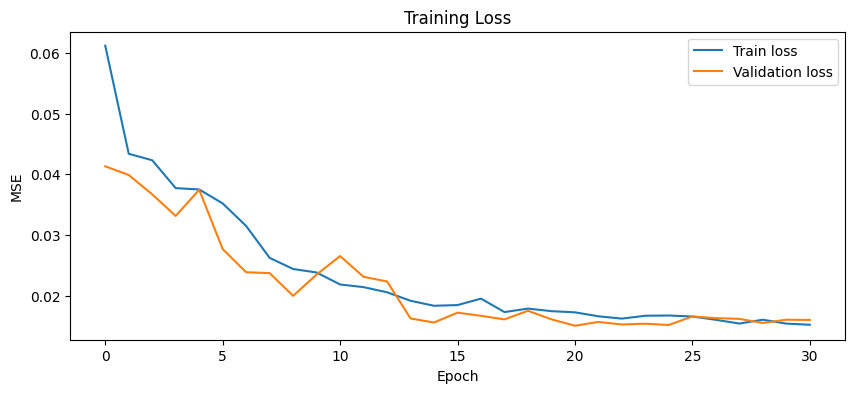

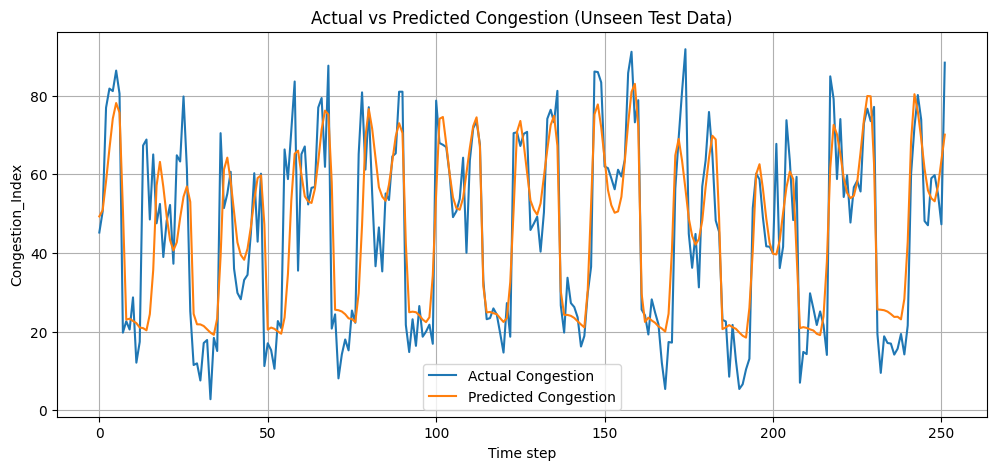

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.random.set_seed(42)
np.random.seed(42)

model = Sequential([
    Input(shape=(WINDOW_SIZE, X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
learning_rate_reducer = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=100, batch_size=32,
                    callbacks=[early_stopping, learning_rate_reducer], verbose=1)

target_minimum = feature_scaler.data_min_[target_index]
target_maximum = feature_scaler.data_max_[target_index]
def inverse_target(scaled_array):
    return scaled_array * (target_maximum - target_minimum) + target_minimum

def evaluate(inputs, outputs, name):
    predicted = inverse_target(model.predict(inputs, verbose=0).flatten())
    actual = inverse_target(outputs)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    print(f"{name:16s} MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}")
    return actual, predicted

evaluate(X_train, y_train, "Train")
evaluate(X_val, y_val, "Validation")
actual_test, predicted_test = evaluate(X_test, y_test, "Test (unseen)")
baseline_mae = mean_absolute_error(actual_test[1:], actual_test[:-1])
baseline_rmse = np.sqrt(mean_squared_error(actual_test[1:], actual_test[:-1]))
print(f"Baseline (previous value) MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}")

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

plt.figure(figsize=(12, 5))
plt.plot(actual_test, label="Actual Congestion")
plt.plot(predicted_test, label="Predicted Congestion")
plt.title("Actual vs Predicted Congestion (Unseen Test Data)")
plt.xlabel("Time step"); plt.ylabel(TARGET_COLUMN); plt.legend(); plt.grid(True); plt.show()